# **Inverse Modeling of Norway 3D Model (inverse permeability)**
- ### **Condition**: low-resolution or noisy $S_g$ (time-lapse seismic monitoring)
- ### **Condition**: partial obervations of $S_g$ and $P$ (monitoring wells)
- ### **Condition**: partial obervations of $S_g$, $P$, and $K$ (monitoring wells and well logs)

In [1]:
%env CUDA_VISIBLE_DEVICES = 0
import torch
import numpy as np
import matplotlib.pyplot as plt
from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    dev = "cuda"
else:
    dev = "cpu"

device = torch.device(dev)
print(device)

from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]


rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)


x = rgb_points[:, 0]

r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]

colors = list(zip(x, zip(r, g, b)))

mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)

env: CUDA_VISIBLE_DEVICES=0
cuda


### Load Unconditional Model

In [3]:
u_net_model = create_model(image_size= 256,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_norway_3D/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

loaded unet


# **Condition**: low-resolution or noisy $S_g$ (time-lapse seismic monitoring)

### Conditional Operator and Noise

In [17]:
operator =  get_operator(name='norway3d_superresolution',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Norway/all3/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Norway/all3/normalizer_params.pt',
                        simdata_path='../../../Dataset/Norway_all3.npy',
                        simdata_idx=1999,
                        ds_size=(32, 59),
                        vanilla_flag=True,
                        noise_level=0.0,
                        time_start_idx=0,
                        time_end_idx=128,
                        time_stride=1,
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:1031: UserWarning: Vanilla flag is set to True, using the original data without downsampling!
  warnings.warn(f"Vanilla flag is set to True, using the original data without downsampling!")


[**Full case**] Using the full time range from 0 to 128 with stride 1.
Simulation data loaded, with shape (128, 64, 118, 3)


### Conditioning Method and Sampler

In [18]:
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='vanilla', scale=1.e-2)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

### Generate Samples

In [5]:
no_of_samples = 4
time_length = 128
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [10]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
# torch.save(gen_latents, 'Norway_outputs/pts/generated_latents_SR(full_case).pt')

Generated latents shape: torch.Size([4, 128, 256])


### Decoding latents to flow fields

In [7]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=15,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Norway/all3/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [12]:
nf_out_gene = []
# gen_latents = torch.load('Norway_outputs/pts/generated_latents_SR(full_case).pt')
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
for i in range(4):
    gene_latents_one = gen_latents[i:i+1]
    gene_latents_one = rearrange(gene_latents_one, 'b t l -> (b t) 1 1 l')
    gene_latents_one = gene_latents_one.to(device)
    with torch.no_grad():
        nf_out_one = nf(whole_coords_in, gene_latents_one)
    nf_out_one = operator._unnorm_cnf(nf_out_one)
    nf_out_one = nf_out_one.reshape(1, 128, 64, 118, 3)
    nf_out_gene.append(nf_out_one)
nf_out_gene = torch.cat(nf_out_gene, dim=0)

# whole_coords = operator._gene_cartesian_coord()
# whole_coords_in = whole_coords.unsqueeze(0).to(device)
# gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
# gen_latents_in = gen_latents_in.to(device)
# with torch.no_grad():
#     nf_out_gene = nf(whole_coords_in, gen_latents_in)
# nf_out_gene = operator._unnorm_cnf(nf_out_gene)
# nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 118, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'Norway_outputs/pts/CNF_out_Uncond.pt')
np.save('Norway_outputs/npys/CNF_out_Uncond.npy', nf_out_gene.detach().cpu().numpy())

CNF output shape: torch.Size([4, 128, 64, 118, 3])


### A branch for posterior check for plume conditioning
- to explain the discrepency

(128, 64, 118, 3)


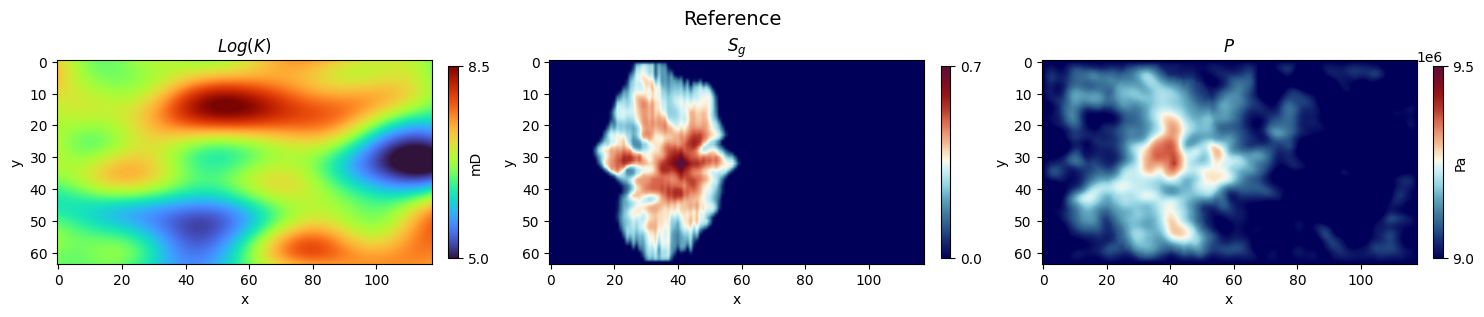

In [2]:
def make1x3(K, S, P, figsize=(18, 5)):
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    
    im0 = axs[0].imshow(K, cmap='turbo', interpolation='bilinear', vmin=5, vmax=8.5)
    cbar0 = plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04, shrink=0.5)
    cbar0.set_ticks([5, 8.5])
    cbar0.set_label('mD', labelpad=-15)
    axs[0].set_title('$Log(K)$')
    
    im1 = axs[1].imshow(S, cmap=mycmap, interpolation='bilinear', vmin=0, vmax=0.7)
    cbar1 = plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04, shrink=0.5)
    cbar1.set_ticks([0, 0.7])
    axs[1].set_title('$S_g$')
    
    im2 = axs[2].imshow(P, cmap=mycmap, interpolation='bilinear', vmin=9e6, vmax=9.5e6)
    cbar2 = plt.colorbar(im2, ax=axs[2], fraction=0.046, pad=0.04, shrink=0.5)
    cbar2.set_ticks([9e6, 9.5e6])
    cbar2.set_label('Pa', labelpad=-15)
    axs[2].set_title('$P$')
    
    for ax in axs:
        ax.set_xlabel('x')
        ax.set_ylabel('y')    
    return fig, axs


rr = np.load('Norway_outputs/npys/ref.npy')
print(rr.shape)
ref_K = rr[0, :, :, -1]
ref_S = rr[-1, :, :, 1]
ref_P = rr[-1, :, :, 0]
fig, axs = make1x3(ref_K, ref_S, ref_P)
fig.suptitle('Reference', fontsize=14, y=0.8)
fig.savefig('Norway_outputs/[rebuttle]posterior_check/reference.pdf', bbox_inches='tight', pad_inches=0.0)
plt.show()

In [3]:
aa = np.load('Norway_outputs/npys/CNF_out_SR(full_case).npy')
print(aa.shape)
print('will be sent to numerical solver for evaluation')

import h5py
f = h5py.File('Norway_outputs/npys/Norway_posterior_check_full_plume_condition.hdf5')
print(f.keys())
sim_k = f['permeability_log'][:]
sim_s = f['saturation'][:]
sim_p = f['pressure'][:]
print(sim_k.shape, sim_s.shape, sim_p.shape)

(10, 128, 64, 118, 3)
will be sent to numerical solver for evaluation
<KeysViewHDF5 ['permeability', 'permeability_log', 'pressure', 'saturation', 'time_step']>
(10, 64, 118) (10, 128, 64, 118) (10, 128, 64, 118)


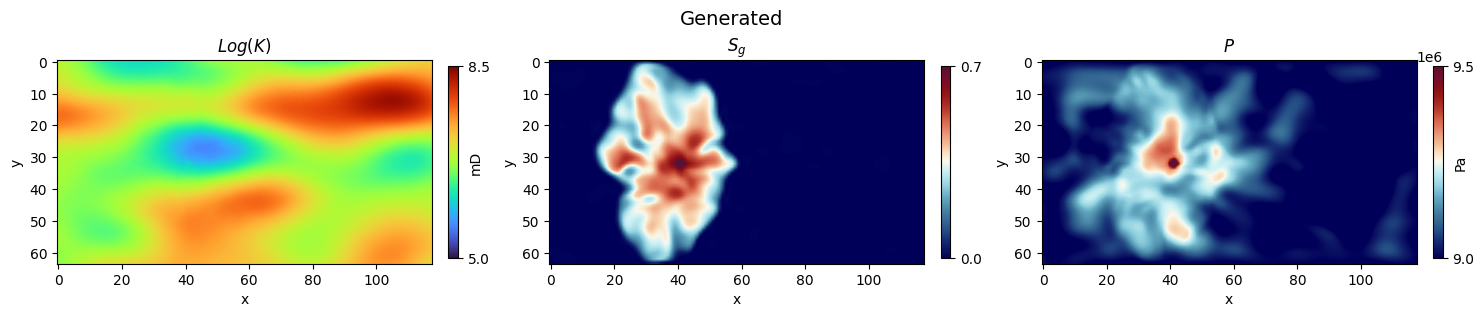

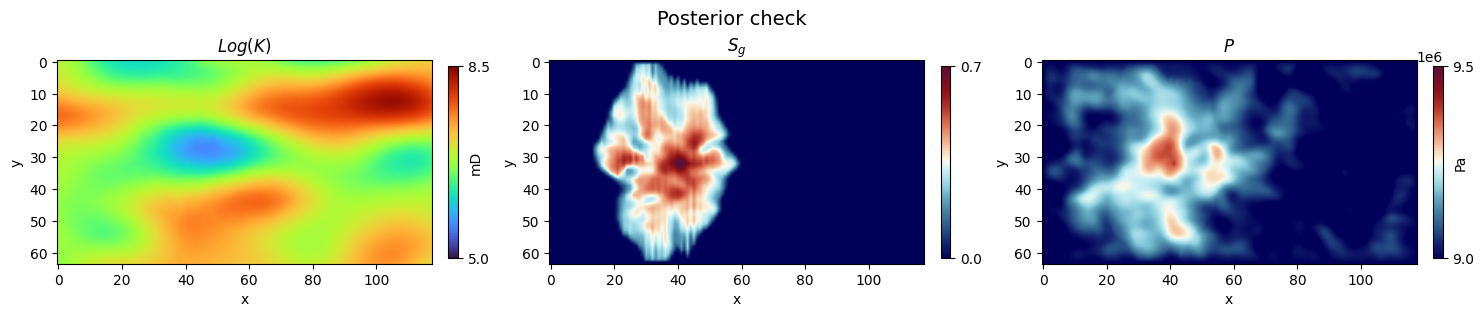

In [4]:
idx = 0
gene_k = aa[idx, :, :, :, -1].mean(axis=0)
gene_s = aa[idx, -1, :, :, 1]
gene_p = aa[idx, -1, :, :, 0]

fig, axs = make1x3(gene_k, gene_s, gene_p)
fig.suptitle('Generated', fontsize=14, y=0.8)
fig.savefig('Norway_outputs/[rebuttle]posterior_check/generation.pdf', bbox_inches='tight', pad_inches=0.0)


fig, axs = make1x3(sim_k[idx], sim_s[idx, -1], sim_p[idx, -1])
fig.suptitle('Posterior check', fontsize=14, y=0.8)
fig.savefig('Norway_outputs/[rebuttle]posterior_check/posterior_check.pdf', bbox_inches='tight', pad_inches=0.0)

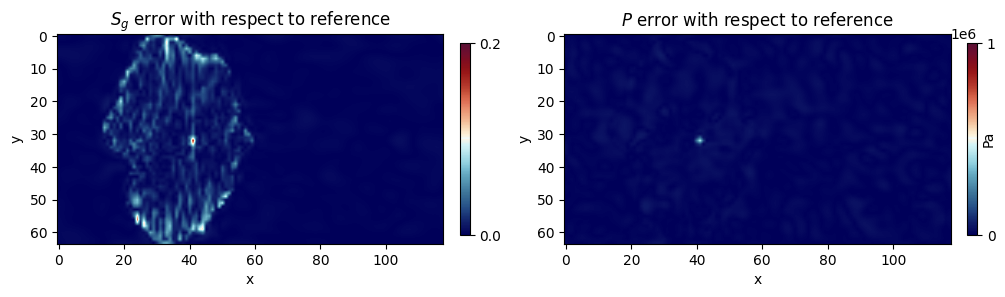

In [82]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

im1 = axs[0].imshow(np.abs(gene_s - ref_S), cmap=mycmap, interpolation='bilinear', vmin=0, vmax=0.2)
cbar1 = plt.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04, shrink=0.5)
cbar1.set_ticks([0, 0.2])
axs[0].set_title('$S_g$ error with respect to reference')

im2 = axs[1].imshow(np.abs(gene_p - ref_P), cmap=mycmap, interpolation='bilinear', vmin=0, vmax=1e6)
cbar2 = plt.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, shrink=0.5)
cbar2.set_ticks([0, 1e6])
cbar2.set_label('Pa', labelpad=-10)
axs[1].set_title('$P$ error with respect to reference')

for ax in axs:
    ax.set_xlabel('x')
    ax.set_ylabel('y')   
plt.savefig('Norway_outputs/[rebuttle]posterior_check/error_with_reference.pdf', bbox_inches='tight', pad_inches=0.0)

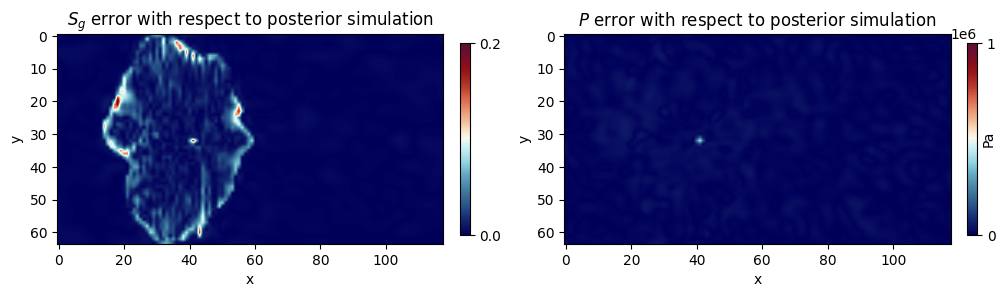

In [83]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

im1 = axs[0].imshow(np.abs(gene_s - sim_s[idx, -1]), cmap=mycmap, interpolation='bilinear', vmin=0, vmax=0.2)
cbar1 = plt.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04, shrink=0.5)
cbar1.set_ticks([0, 0.2])
axs[0].set_title('$S_g$ error with respect to posterior simulation')

im2 = axs[1].imshow(np.abs(gene_p - sim_p[idx, -1]), cmap=mycmap, interpolation='bilinear', vmin=0, vmax=1e6)
cbar2 = plt.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04, shrink=0.5)
cbar2.set_ticks([0, 1e6])
cbar2.set_label('Pa', labelpad=-10)
axs[1].set_title('$P$ error with respect to posterior simulation')

for ax in axs:
    ax.set_xlabel('x')
    ax.set_ylabel('y')
plt.savefig('Norway_outputs/[rebuttle]posterior_check/error_with_posterior_simulation.pdf', bbox_inches='tight', pad_inches=0.0)  

In [84]:
import h5py
f = h5py.File('../../../Dataset/Norway_3D.hdf5')
print(f.keys())
sim_k = f['permeability_log'][:]
sim_s = f['saturation'][:]
sim_p = f['pressure'][:]
print(sim_k.shape, sim_s.shape, sim_p.shape)

<KeysViewHDF5 ['permeability', 'permeability_log', 'pressure', 'saturation', 'time_step']>
(3000, 64, 118) (3000, 128, 64, 118) (3000, 128, 64, 118)


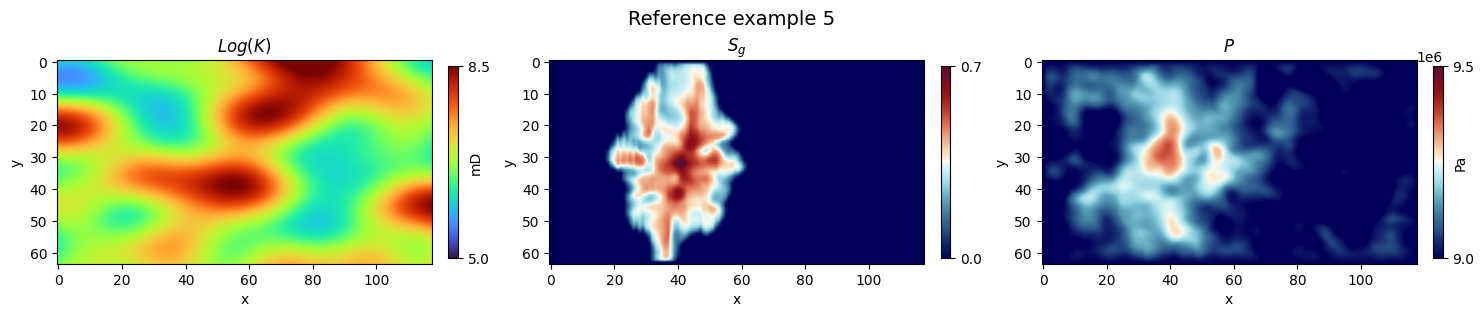

In [89]:
idx = 2500
fig, axs = make1x3(sim_k[idx], sim_s[idx, -1], sim_p[idx, -1])
fig.suptitle('Reference example 5', fontsize=14, y=0.8)
fig.savefig(f'Norway_outputs/[rebuttle]posterior_check/reference_example_{idx}.pdf', bbox_inches='tight', pad_inches=0.0)

(64, 118) (64, 118) (10, 128, 64, 118, 3)
(10, 64, 118) (10, 64, 118)
(10, 7552) (10, 7552)


/tmp/ipykernel_2744095/1795688362.py:22: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  axs.scatter(rmse_k[i], rmse_s[i], s=8, alpha=0.5, label=f'Sample {i+1}', c=colors[i], edgecolors='none')


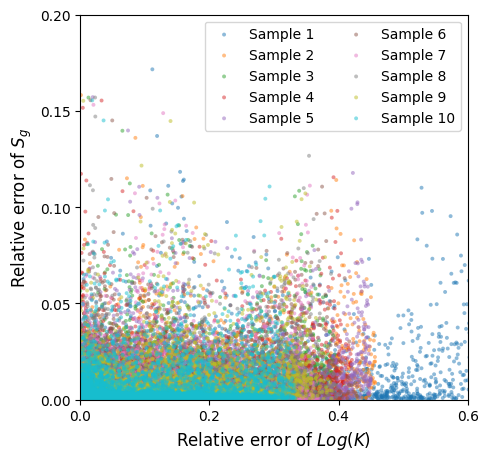

In [51]:
# quantitative correlation analysis

print(ref_K.shape, ref_S.shape, aa.shape)
gene_k_ensemble = aa[:, :, :, :, -1].mean(axis=1)
gene_s_ensemble = aa[:, -1, :, :, 1]
print(gene_k_ensemble.shape, gene_s_ensemble.shape)

def get_rmse(ref_array, gene_array):
    rmse = []
    for i in range(gene_array.shape[0]):
        rmse.append(np.abs(ref_array.flatten() - gene_array[i].flatten()) / np.ptp(ref_array.flatten()))
    return np.array(rmse)

rmse_k = get_rmse(ref_K, gene_k_ensemble)
rmse_s = get_rmse(ref_S, gene_s_ensemble)
print(rmse_k.shape, rmse_s.shape)

fig, axs = plt.subplots(1, 1, figsize=(5, 5))
colors = plt.cm.tab10(np.arange(rmse_k.shape[0]))

for i in range(rmse_k.shape[0]):
    axs.scatter(rmse_k[i], rmse_s[i], s=8, alpha=0.5, label=f'Sample {i+1}', c=colors[i], edgecolors='none')

axs.set_xlabel('Relative error of $Log(K)$', fontsize=12)
axs.set_ylabel('Relative error of $S_g$', fontsize=12)
axs.set_xlim(0, 0.6)
axs.set_ylim(0, 0.2)
axs.set_yticks([0, 0.05, 0.1, 0.15, 0.2])
axs.set_xticks([0, 0.2, 0.4, 0.6])
axs.legend(fontsize=10, loc='upper right', ncol=2)

fig.savefig(f'Norway_outputs/[rebuttle]posterior_check/quantitative_correlation_analyze.png', bbox_inches='tight', pad_inches=0.0, dpi=600)

### ***Load pt records (CNF out & reference)***

In [20]:
# sr4 = torch.load('conditional_outputs/pts/CNF_out_Cart4xSR.pt', map_location='cpu').detach().numpy()
# sr8 = torch.load('conditional_outputs/pts/CNF_out_Cart8xSR.pt', map_location='cpu').detach().numpy()
# sr16 = torch.load('conditional_outputs/pts/CNF_out_Cart16xSR.pt', map_location='cpu').detach().numpy()
sr64 = torch.load('Norway_outputs/pts/CNF_out_SR(full_case).pt', map_location='cpu').detach().numpy()
# ref = operator.retrieve_data()['simdata']
# condition = operator.retrieve_data()['up_measurement']
# print(f"Reference shape: {ref.shape}, measurement shape: {condition.shape}, CNF output shape: {sr64.shape}")

*plot maps*

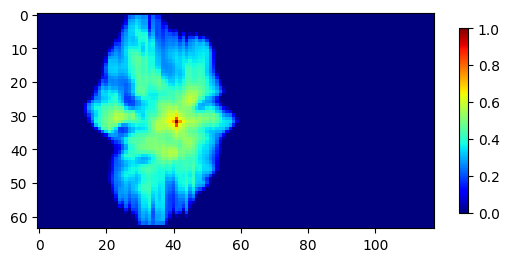

In [18]:
plt.imshow(condition[-1,..., 1], cmap='jet')
plt.colorbar(shrink=0.5)

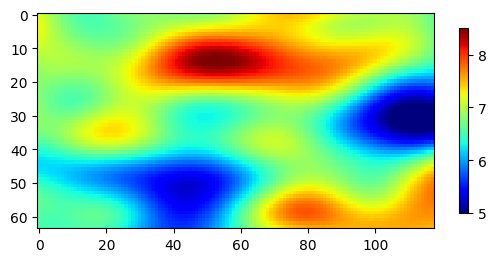

In [19]:
plt.imshow(ref[-1, ...,2], cmap='jet', vmin=5, vmax=8.5)
plt.colorbar(shrink=0.5)

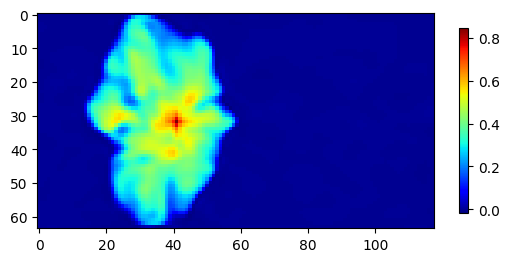

In [30]:
plt.imshow(sr64[3, -1, ...,1], cmap='jet')
plt.colorbar(shrink=0.5)

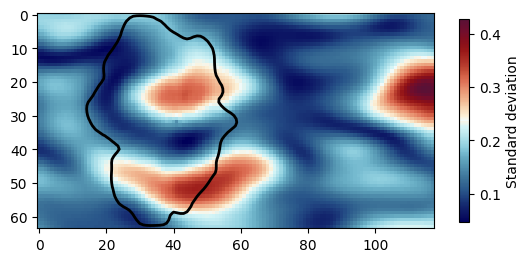

In [68]:
field = sr64[3, -1, ..., 1]
# im = plt.imshow(field, cmap='jet')
plt.contour(field, levels=[0.1], colors='k', linewidths=2)
# plt.colorbar(im)


plt.imshow(np.std(np.mean(sr64[:, :, ...,2], axis=1), axis=0), cmap=mycmap)
plt.colorbar(shrink=0.55, label='Standard deviation')
plt.savefig("Norway_outputs/[rebuttle]figs/case3_K_std[R3-C4].pdf", bbox_inches='tight')
plt.show()

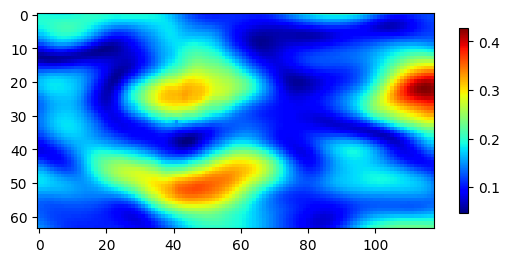

In [37]:
plt.imshow(np.std(np.mean(sr64[:, :, ...,2], axis=1), axis=0), cmap='jet')
plt.colorbar(shrink=0.5)

In [48]:
a = torch.load("../Cartesian/conditional_outputs/pts/CNF_out_Cart64xSR.pt", map_location='cpu').numpy()
print(a.shape)

(10, 64, 64, 64, 3)


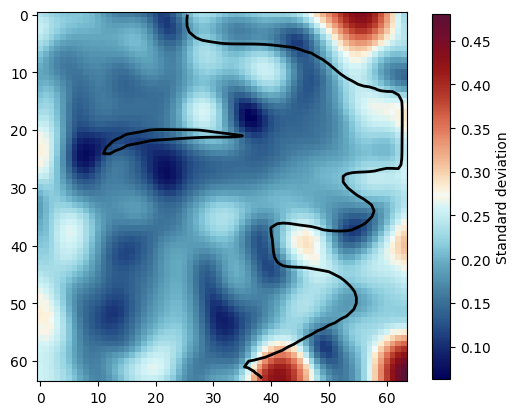

In [67]:
field = a[0, -1, ..., 1]
plt.contour(field, levels=[0.1], colors='k', linewidths=2)

plt.imshow(np.std(np.mean(a[:, :, ...,2], axis=1), axis=0), cmap=mycmap)
plt.colorbar(shrink=0.99,label='Standard deviation')
plt.savefig("Norway_outputs/[rebuttle]figs/case1_K_std[R3-C4].pdf", bbox_inches='tight')

# **Condition**: partial obervations of $S_g$, $P$, and $K$ (monitoring wells and well logs)

### Operator and Sampler

In [4]:
operator =  get_operator(name='norway3d_sparse_measurement_all',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Norway/all3/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Norway/all3/normalizer_params.pt',
                        simdata_path='../../../Dataset/Norway_all3.npy',
                        simdata_idx=1999,
                        num_probed=(3, 6),
                        min_range=(10, 10),
                        max_range=(53, 107),
                        time_start_idx=0,
                        time_end_idx=96,
                        time_stride=1,
                        noise_level=0.0
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

query_pts = operator.query_points
print(f"Query points: {query_pts}")
np.save('Norway_outputs/npys/query_pts_18.npy', np.array(query_pts))

noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # \lambda=1
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                        steps=1000,
                        noise_schedule="cosine",
                        model_mean_type="epsilon",
                        model_var_type="learned_range",
                        dynamic_threshold=False,
                        clip_denoised=True,
                        rescale_timesteps=False,
                        timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:473: UserWarning: Uniformed generated (3, 6) points for measurement, please check the results.
  warnings.warn(f"Uniformed generated {num_probed} points for measurement, please check the results.")


[**Half case**] Using the time range from 0 to 96 with stride 1.
Simulation data loaded, with shape (128, 64, 118, 3)
Query points: [(np.int64(10), np.int64(10)), (np.int64(10), np.int64(29)), (np.int64(10), np.int64(48)), (np.int64(10), np.int64(68)), (np.int64(10), np.int64(87)), (np.int64(10), np.int64(107)), (np.int64(31), np.int64(10)), (np.int64(31), np.int64(29)), (np.int64(31), np.int64(48)), (np.int64(31), np.int64(68)), (np.int64(31), np.int64(87)), (np.int64(31), np.int64(107)), (np.int64(53), np.int64(10)), (np.int64(53), np.int64(29)), (np.int64(53), np.int64(48)), (np.int64(53), np.int64(68)), (np.int64(53), np.int64(87)), (np.int64(53), np.int64(107))]


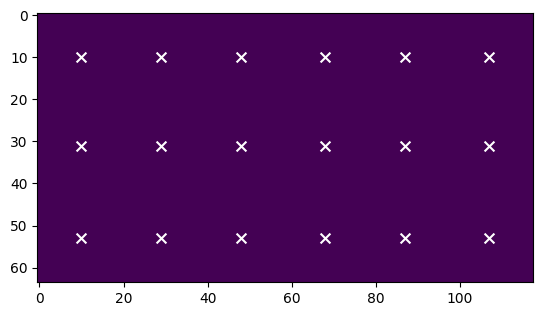

In [5]:
plt.imshow(np.zeros((64, 118)))
for y,x in query_pts:
    plt.scatter(x, y, c='white', s=50, marker='x')

### Generation

In [11]:
no_of_samples = 10
time_length = 128
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Measurement shape: torch.Size([128, 18, 3])


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

...

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

### Save generated latents

In [12]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
# torch.save(gen_latents, 'Norway_outputs/pts/generated_latents_Sparse6_allt_0.pt')

Generated latents shape: torch.Size([10, 128, 256])


### Decoding by CNF

In [13]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=15,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Norway/all3/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [14]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 118, 3)
print(f"CNF output shape: {nf_out_gene.shape}")

# ! change save name !!!
torch.save(nf_out_gene, 'Norway_outputs/pts/CNF_out_Sparse_18_75%t_0.pt')
np.save('Norway_outputs/npys/CNF_out_Sparse_18_75%t_0.npy', nf_out_gene.detach().cpu().numpy())

CNF output shape: torch.Size([10, 128, 64, 118, 3])


In [5]:
# sr4 = torch.load('conditional_outputs/pts/CNF_out_Cart4xSR.pt', map_location='cpu').detach().numpy()
# sr8 = torch.load('conditional_outputs/pts/CNF_out_Cart8xSR.pt', map_location='cpu').detach().numpy()
# sr16 = torch.load('conditional_outputs/pts/CNF_out_Cart16xSR.pt', map_location='cpu').detach().numpy()
sr64 = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_allt_0.pt', map_location='cpu').detach().numpy()
ref = operator.retrieve_data()['simdata']
condition = operator.retrieve_data()['measurement']
print(f"Reference shape: {ref.shape}, measurement shape: {condition.shape}, CNF output shape: {sr64.shape}")

AttributeError: 'Norway3DOperatorSM' object has no attribute 'unnormed_measurements'

In [ ]:
np.save('Norway_outputs/npys/ref.npy', ref)

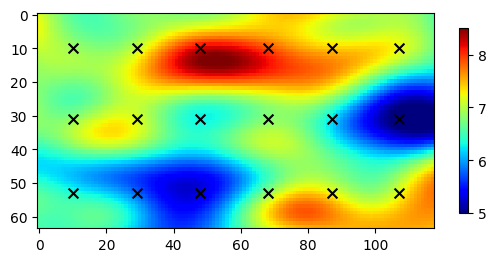

In [ ]:
plt.imshow(ref[-1, ...,2], cmap='jet', vmin=5, vmax=8.5)
plt.colorbar(shrink=0.5)
for y,x in query_pts:
    plt.scatter(x, y, c='black', s=50, marker='x')

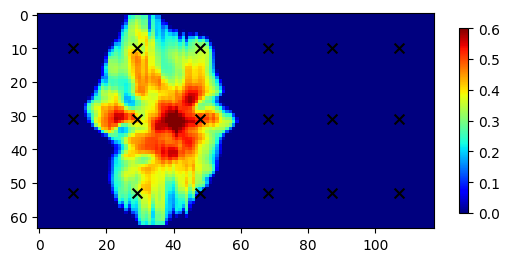

In [ ]:
plt.imshow(ref[-1, ...,1], cmap='jet', vmin=0, vmax=0.6)
plt.colorbar(shrink=0.5)
for y,x in query_pts:
    plt.scatter(x, y, c='black', s=50, marker='x')


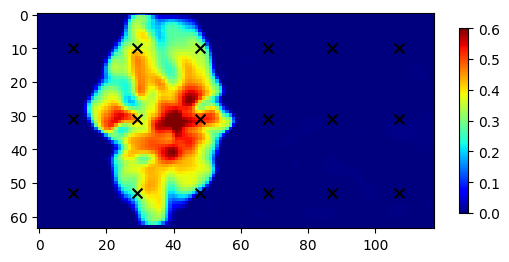

In [ ]:
plt.imshow(np.mean(sr64[:, -1, ...,1], axis=0), cmap='jet', vmin=0, vmax=0.6)
plt.colorbar(shrink=0.5)
for y,x in query_pts:
    plt.scatter(x, y, c='black', s=50, marker='x')

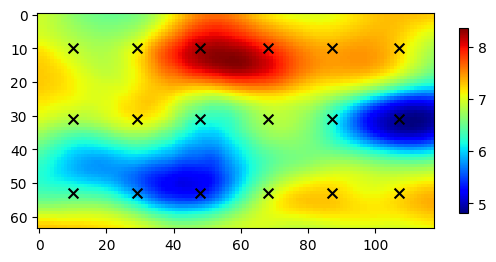

In [16]:
plt.imshow(np.mean(sr64[1, :, ...,2], axis=0), cmap='jet')
plt.colorbar(shrink=0.5)
for y,x in query_pts:
    plt.scatter(x, y, c='black', s=50, marker='x')


## Plot statistical figures ...

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [7]:
REF = np.load('Norway_outputs/npys/ref.npy')
sparse_6 = torch.load('Norway_outputs/pts/CNF_out_Sparse_6_allt_0.pt', map_location='cpu').detach().numpy()
sparse_18 = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_allt_0.pt', map_location='cpu').detach().numpy()
sr = torch.load('Norway_outputs/pts/CNF_out_SR(full_case).pt', map_location='cpu').detach().numpy()
print(f"Reference shape: {REF.shape}, sparse_6 shape: {sparse_6.shape}, sparse_18 shape: {sparse_18.shape}, sr shape: {sr.shape}")

Reference shape: (128, 64, 118, 3), sparse_6 shape: (10, 128, 64, 118, 3), sparse_18 shape: (10, 128, 64, 118, 3), sr shape: (10, 128, 64, 118, 3)


In [8]:
def get_ensemble_k(gene):
    ensemble_k = []
    for i in range(gene.shape[0]):
        ensemble_k.append(np.mean(gene[i, :, ..., 2], axis=0))
    return np.array(ensemble_k)
sparse_6_k = get_ensemble_k(sparse_6)
sparse_18_k = get_ensemble_k(sparse_18)
sr_k = get_ensemble_k(sr)
print(f"sparse_6_k shape: {sparse_6_k.shape}, sparse_18_k shape: {sparse_18_k.shape}, sr_k shape: {sr_k.shape}")

sparse_6_k shape: (10, 64, 118), sparse_18_k shape: (10, 64, 118), sr_k shape: (10, 64, 118)


injection well idx: (np.int64(32), np.int64(41))


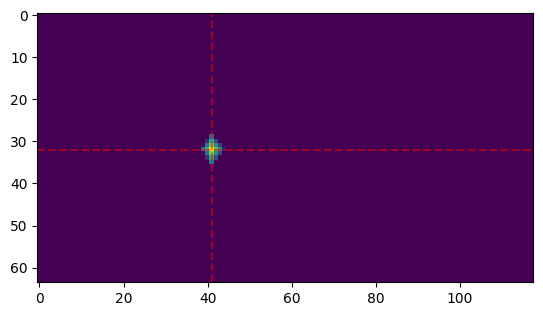

In [11]:
idx_multi = np.unravel_index(np.argmax(REF[0, ..., 1]), REF[0, ..., 1].shape)
print(f'injection well idx: {idx_multi}')
plt.imshow(REF[0, ..., 1])
plt.axhline(y=32, color='r', linestyle='--', alpha=0.5)
plt.axvline(x=41, color='r', linestyle='--', alpha=0.5)

In [9]:
def plot_mean_and_std(data, label, color, ls, alpha=0.2):
    mean_data = np.mean(data, axis=0)
    std_data = np.std(data, axis=0)
    plt.plot(mean_data, label=label, color=color, linestyle=ls, linewidth=1.5)
    plt.fill_between(range(mean_data.shape[0]), mean_data - std_data, mean_data + std_data, color=color, alpha=alpha, edgecolor='none')

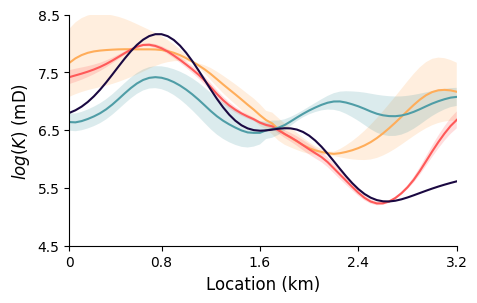

In [176]:
plt.figure(figsize=(5, 3))  #originally (5, 3)
plot_mean_and_std(sparse_6_k[:, :, 41], label='6 monitoring wells', color='#ffad5a', ls='-')
plot_mean_and_std(sparse_18_k[:, :, 41], label='18 monitoring wells', color='#ff5959', ls='-')
plot_mean_and_std(sr_k[:, :, 41], label='$CO_2$ plume monitoring', color="#4f9da6", ls='-')
plt.plot(np.arange(64), REF[0, :, 41, 2], label='Reference', color='#1a0841', linestyle='-', linewidth=1.5)
plt.xlabel('Location (km)', fontsize=12)
plt.ylabel('$log(K)$ (mD)', fontsize=12)
# plt.legend(frameon=False, loc='lower left', fontsize=10, ncol=1, bbox_to_anchor=(0.0, -0.05))
plt.xlim(0, 63)
plt.ylim(4.5, 8.5)
plt.yticks([4.5, 5.5, 6.5, 7.5, 8.5])
phys_labels = [0, 0.8, 1.6, 2.4, 3.2]
xticks = [int(x * 63 / 3.2) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)
# plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('Norway_outputs/[rebuttle]figs/K_line_monitoring_type.pdf', bbox_inches='tight')
plt.show()

In [104]:
def eval_vario(field):
    import gstools as gs
    x = np.arange(1, 65) * 50
    y = np.arange(1, 119) * 50
    bin, gamma = gs.vario_estimate(
        *((x, y),),
        field,
        mesh_type='structured',
        direction=((0, 1),)
    )
    fit_model = gs.Gaussian(dim=2)
    fit_model.fit_variogram(bin, gamma, nugget=False)
    return bin, gamma, fit_model

def eval_vario_samples(fields):
    bin_list, gamma_list, fit_model_list = [], [], []
    for i in range(fields.shape[0]):
        bin, gamma, fit_model = eval_vario(fields[i])
        bin_list.append(bin)
        gamma_list.append(gamma)
        fit_model_list.append(fit_model)
    return bin_list, gamma_list, fit_model_list

gt_bin, gt_gamma, gt_fit_model = eval_vario(REF[0, ..., 2])
sparse_6_bin, sparse_6_gamma, sparse_6_fit_model = eval_vario_samples(sparse_6_k)
sparse_18_bin, sparse_18_gamma, sparse_18_fit_model = eval_vario_samples(sparse_18_k)
sr_bin, sr_gamma, sr_fit_model = eval_vario_samples(sr_k)

gt_bin, gt_gamma, gt_fit_model

(array([  41.01339739,  123.04019217,  205.06698695,  287.09378173,
         369.12057651,  451.14737128,  533.17416606,  615.20096084,
         697.22775562,  779.2545504 ,  861.28134518,  943.30813996,
        1025.33493474, 1107.36172952, 1189.3885243 , 1271.41531908,
        1353.44211385, 1435.46890863, 1517.49570341, 1599.52249819,
        1681.54929297, 1763.57608775, 1845.60288253, 1927.62967731,
        2009.65647209, 2091.68326687, 2173.71006165]),
 array([0.00075291, 0.00744115, 0.0141235 , 0.02892731, 0.04435093,
        0.06861181, 0.09234323, 0.11838641, 0.14844767, 0.17896888,
        0.21346308, 0.24623192, 0.27122345, 0.31044291, 0.33254887,
        0.36096022, 0.40085217, 0.41372745, 0.44079999, 0.46962598,
        0.47577936, 0.50099703, 0.51699031, 0.51689051, 0.53608957,
        0.53616364, 0.5406646 ]),
 Gaussian(dim=2, var=0.58, len_scale=1.13e+03, nugget=0.0))

In [129]:
sparse_18_fit_model[0]

Gaussian(dim=2, var=0.481, len_scale=1.23e+03, nugget=0.0)

In [111]:
def dykstra_parsons(k):
    if k.ndim == 2:
        k = k.reshape(-1)
        k16 = np.quantile(k, 0.16)
        k50 = np.quantile(k, 0.5)
        dp = (k50 - k16) / k50
    elif k.ndim == 3:
        dp = np.array([(np.quantile(k[i], 0.5) - np.quantile(k[i], 0.16)) / np.quantile(k[i], 0.5) 
                        for i in range(k.shape[0])])
    return dp

gt_dp = dykstra_parsons(REF[0, ..., 2])
sparse_6_dp = dykstra_parsons(sparse_6_k)
sparse_18_dp = dykstra_parsons(sparse_18_k)
sr_dp = dykstra_parsons(sr_k)
print(f"Reference DP: {gt_dp}, Sparse 6 DP: {sparse_6_dp}, Sparse 18 DP: {sparse_18_dp}, SR DP: {sr_dp}")

Reference DP: 0.11243646591901779, Sparse 6 DP: [0.06692152 0.06318081 0.0773548  0.06094149 0.0584338  0.06930989
 0.08631835 0.05241082 0.05839307 0.06487698], Sparse 18 DP: [0.11413936 0.1260426  0.11486581 0.11532784 0.12018633 0.11780442
 0.11712673 0.11830921 0.1188655  0.10925313], SR DP: [0.05846671 0.06845587 0.06257787 0.05947414 0.07025668 0.06298956
 0.05987241 0.05866272 0.05927139 0.06635273]


In [130]:
sparse_6_bin_plot, sparse_6_gamma_plot, sparse_6_cor_len = [], [], []
sparse_18_bin_plot, sparse_18_gamma_plot, sparse_18_cor_len = [], [], []
sr_bin_plot, sr_gamma_plot, sr_cor_len = [], [], []
for i in range(sparse_6_k.shape[0]):
    sparse_6_bin_plot.append(sparse_6_bin[i])
    sparse_6_gamma_plot.append(sparse_6_fit_model[i].variogram(sparse_6_bin[i]))
    sparse_6_cor_len.append(sparse_6_fit_model[i].len_scale)
    
    sparse_18_bin_plot.append(sparse_18_bin[i])
    sparse_18_gamma_plot.append(sparse_18_fit_model[i].variogram(sparse_18_bin[i]))
    sparse_18_cor_len.append(sparse_18_fit_model[i].len_scale)
    
    sr_bin_plot.append(sr_bin[i])
    sr_gamma_plot.append(sr_fit_model[i].variogram(sr_bin[i]))
    sr_cor_len.append(sr_fit_model[i].len_scale)
print(len(sparse_6_bin_plot), sparse_6_bin_plot[0].shape, sparse_6_gamma_plot[0].shape)    

10 (27,) (27,)


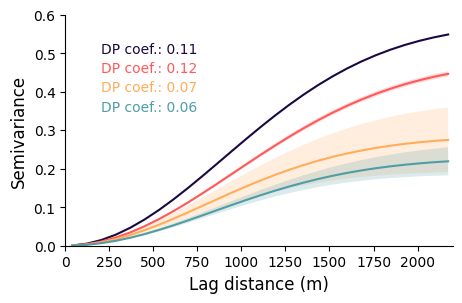

In [177]:
plt.figure(figsize=(5, 3))
plt.plot(gt_bin, gt_fit_model.variogram(gt_bin), label='Reference', color='#1a0841', linestyle='-', linewidth=1.5)

plt.plot(gt_bin, np.mean(sparse_18_gamma_plot, axis=0), label='18 monitoring wells', color='#ff5959', linestyle='-', linewidth=1.5)
plt.plot(gt_bin, np.mean(sparse_6_gamma_plot, axis=0), label='6 monitoring wells', color='#ffad5a', linestyle='-', linewidth=1.5)
plt.plot(gt_bin, np.mean(sr_gamma_plot, axis=0), label='Super-resolution', color='#4f9da6', linestyle='-', linewidth=1.5)

plt.fill_between(gt_bin, np.mean(sparse_18_gamma_plot, axis=0) - np.std(sparse_18_gamma_plot, axis=0), np.mean(sparse_18_gamma_plot, axis=0) + np.std(sparse_18_gamma_plot, axis=0), color='#ff5959', alpha=0.2, edgecolor='none')
plt.fill_between(gt_bin, np.mean(sparse_6_gamma_plot, axis=0) - np.std(sparse_6_gamma_plot, axis=0), np.mean(sparse_6_gamma_plot, axis=0) + np.std(sparse_6_gamma_plot, axis=0), color='#ffad5a', alpha=0.2, edgecolor='none')
plt.fill_between(gt_bin, np.mean(sr_gamma_plot, axis=0) - np.std(sr_gamma_plot, axis=0), np.mean(sr_gamma_plot, axis=0) + np.std(sr_gamma_plot, axis=0), color='#4f9da6', alpha=0.2, edgecolor='none')


# plt.fill_between(gt_bin, np.min(sparse_6_gamma_plot, axis=0), np.max(sparse_6_gamma_plot, axis=0), color='#ffad5a', alpha=0.2, edgecolor='none')
# plt.fill_between(gt_bin, np.min(sparse_18_gamma_plot, axis=0), np.max(sparse_18_gamma_plot, axis=0), color='#007acc', alpha=0.2, edgecolor='none')
# plt.fill_between(gt_bin, np.min(sr_gamma_plot, axis=0), np.max(sr_gamma_plot, axis=0), color='#ff5722', alpha=0.2, edgecolor='none')
plt.text(200, 0.5, f"DP coef.: {gt_dp:.2f}", color='#1a0841', fontsize=10)
plt.text(200, 0.45, f"DP coef.: {np.mean(sparse_18_dp):.2f}", color='#ff5959', fontsize=10)
plt.text(200, 0.40, f"DP coef.: {np.mean(sparse_6_dp):.2f}", color='#ffad5a', fontsize=10)
plt.text(200, 0.35, f"DP coef.: {np.mean(sr_dp):.2f}", color='#4f9da6', fontsize=10)

plt.xlabel('Lag distance (m)', fontsize=12)
plt.ylabel('Semivariance', fontsize=12)
plt.xlim(0, 2200)
plt.ylim(0, 0.6)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('Norway_outputs/[rebuttle]figs/variogram_diff_monitoring.pdf', bbox_inches='tight')
plt.show()

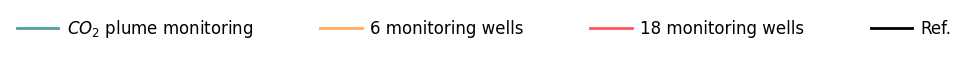

In [316]:
# 自定义 6 个图例元素
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#4f9da6', lw=2, ls='-', label='$CO_2$ plume monitoring'),
    Line2D([0], [0], color='#ffad5a', lw=2, ls='-', label='6 monitoring wells'),
    Line2D([0], [0], color='#ff5959', lw=2, ls='-', label='18 monitoring wells'),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Ref.'),
]

# 创建一个空的透明 subplot
fig, ax = plt.subplots(figsize=(5, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=4,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=4,  # space between columns
    fontsize=12,
)

# plt.tight_layout()
plt.savefig('Norway_outputs/[rebuttle]figs/LEGEND_LINE_1.pdf', bbox_inches='tight')
plt.show()

# Compare different observaiton history -- 18 wells

In [11]:
REF = np.load('Norway_outputs/npys/ref.npy')
allt = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_allt_0.pt', map_location='cpu').detach().numpy()
quatert = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_25%t_0.pt', map_location='cpu').detach().numpy()
halft = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_50%t_0.pt', map_location='cpu').detach().numpy()
threet = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_75%t_0.pt', map_location='cpu').detach().numpy()
sparset = torch.load('Norway_outputs/pts/CNF_out_Sparse_18_10t_0.pt', map_location='cpu').detach().numpy()

allt_k = get_ensemble_k(allt)
quatert_k = get_ensemble_k(quatert)
halft_k = get_ensemble_k(halft)
threet_k = get_ensemble_k(threet)
sparset_k = get_ensemble_k(sparset)
print(f"allt_k shape: {allt_k.shape}, quatert_k shape: {quatert_k.shape}, halft_k shape: {halft_k.shape}, threet_k shape: {threet_k.shape}, sparset_k shape: {sparset_k.shape}")

allt_k shape: (10, 64, 118), quatert_k shape: (10, 64, 118), halft_k shape: (10, 64, 118), threet_k shape: (10, 64, 118), sparset_k shape: (10, 64, 118)


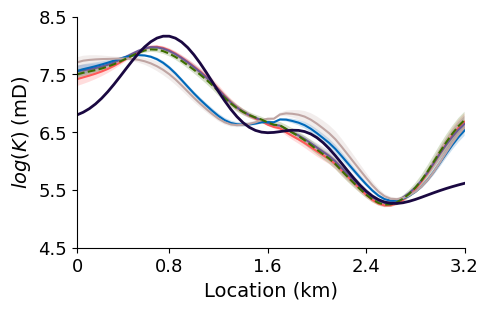

In [14]:

colors = ['#ff5959', '#6c5995', '#0069ba', '#bfa5a3', "#3c6d00"]

plt.figure(figsize=(5, 3))
plot_mean_and_std(allt_k[:, :, 41], label="Full observation", color=colors[0], ls='-')
plot_mean_and_std(threet_k[:, :, 41], label="More partial observation", color=colors[1], ls='-')
plot_mean_and_std(halft_k[:, :, 41], label="Partial observation", color=colors[2], ls='-')
plot_mean_and_std(quatert_k[:, :, 41], label="Less partial observation", color=colors[3], ls='-')
plot_mean_and_std(sparset_k[:, :, 41], label='Sparse observation', color=colors[4], ls='--')

plt.plot(np.arange(64), REF[0, :, 41, 2], label='Reference', color='#1a0841', linestyle='-', linewidth=2)

plt.xlabel('Location (km)', fontsize=14)
plt.ylabel('$log(K)$ (mD)', fontsize=14)
# plt.legend(frameon=False, loc='lower left', fontsize=12, bbox_to_anchor=(0.0, -0.05))
plt.xlim(0, 63)
plt.ylim(4.5, 8.5)
plt.yticks([4.5, 5.5, 6.5, 7.5, 8.5])
phys_labels = [0, 0.8, 1.6, 2.4, 3.2]
xticks = [int(x * 63 / 3.2) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/[rebuttle]figs/K_line_t.pdf', bbox_inches='tight')
plt.show()

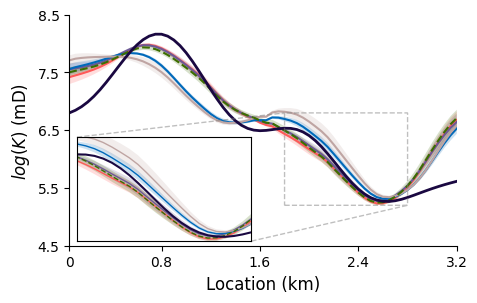

In [15]:
def plot_mean_and_std(data, label=None, color='blue', ls='-', alpha=0.2, ax=None, linewidth=1.5):
    if ax is None:
        ax = plt.gca()
    mean_data = np.mean(data, axis=0)
    std_data = np.std(data, axis=0)
    ax.plot(mean_data, label=label, color=color, linestyle=ls, linewidth=linewidth)
    ax.fill_between(range(mean_data.shape[0]), mean_data - std_data, mean_data + std_data, 
                     color=color, alpha=alpha, edgecolor='none')

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

colors = ['#ff5959', '#6c5995', '#0069ba', '#bfa5a3', "#3c6d00"]

fig, ax = plt.subplots(figsize=(5, 3))

plot_mean_and_std(allt_k[:, :, 41], label="Full observation", color=colors[0], ls='-', ax=ax)
plot_mean_and_std(threet_k[:, :, 41], label="More partial observation", color=colors[1], ls='-', ax=ax)
plot_mean_and_std(halft_k[:, :, 41], label="Partial observation", color=colors[2], ls='-', ax=ax)
plot_mean_and_std(quatert_k[:, :, 41], label="Less partial observation", color=colors[3], ls='-', ax=ax)
plot_mean_and_std(sparset_k[:, :, 41], label='Sparse observation', color=colors[4], ls='--', ax=ax)

ax.plot(np.arange(64), REF[0, :, 41, 2], label='Reference', color='#1a0841', linestyle='-', linewidth=2)

ax.set_xlabel('Location (km)', fontsize=12)
ax.set_ylabel('$log(K)$ (mD)', fontsize=12)
ax.set_xlim(0, 63)
ax.set_ylim(4.5, 8.5)
ax.set_yticks([4.5, 5.5, 6.5, 7.5, 8.5])
phys_labels = [0, 0.8, 1.6, 2.4, 3.2]
xticks = [int(x * 63 / 3.2) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
ax.set_xticks(ticks=xticks, labels=xtick_labels)
# ax.tick_params(axis='both', labelsize=13)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# ---- 局部放大 ----
axins = ax.inset_axes([0.02, 0.02, 0.45, 0.45])

plot_mean_and_std(allt_k[:, :, 41], color=colors[0], ls='-', ax=axins, linewidth=1)
plot_mean_and_std(threet_k[:, :, 41], color=colors[1], ls='-', ax=axins, linewidth=1)
plot_mean_and_std(halft_k[:, :, 41], color=colors[2], ls='-', ax=axins, linewidth=1)
plot_mean_and_std(quatert_k[:, :, 41], color=colors[3], ls='-', ax=axins, linewidth=1)
plot_mean_and_std(sparset_k[:, :, 41], color=colors[4], ls='--', ax=axins, linewidth=1)
axins.plot(np.arange(64), REF[0, :, 41, 2], color='#1a0841', linestyle='-', linewidth=1.5)

x1_idx = int(1.8 * 63 / 3.2)
x2_idx = int(2.8 * 63 / 3.2)
axins.set_xlim(x1_idx, x2_idx)
axins.set_ylim(5.2, 6.8)
axins.set_xticks([])
axins.set_yticks([])

ax.indicate_inset_zoom(axins, edgecolor="0.5", linestyle='--')

plt.savefig('Norway_outputs/[rebuttle]figs/K_line_t.pdf', bbox_inches='tight')
plt.show()

In [81]:
def rmse(a, b):
    return np.sqrt((a - b)**2).mean()

def calculate_sat_rmse(ref, gene):
    rmse_list = []
    ref_sat = ref[..., 1]
    for i in range(gene.shape[0]):
        sat = gene[i, :, ..., 1]
        for t in range(gene.shape[1]):
            rmse_value = rmse(ref_sat[t, ...], sat[t, ...])
            rmse_list.append(rmse_value)
    rmse_list = np.array(rmse_list)
    rmse_List = rmse_list.reshape(gene.shape[0], gene.shape[1])
    rmse_mean = np.mean(rmse_List, axis=0)
    rmse_std = np.std(rmse_List, axis=0)
    return rmse_mean, rmse_std

sr_sat_mean, sr_sat_std = calculate_sat_rmse(REF, sr)
sparse_6_sat_mean, sparse_6_sat_std = calculate_sat_rmse(REF, sparse_6)
sparse_18_sat_mean, sparse_18_sat_std = calculate_sat_rmse(REF, sparse_18)
print(f'mean shape: {sr_sat_mean.shape}, std shape: {sr_sat_std.shape}')

mean shape: (128,), std shape: (128,)


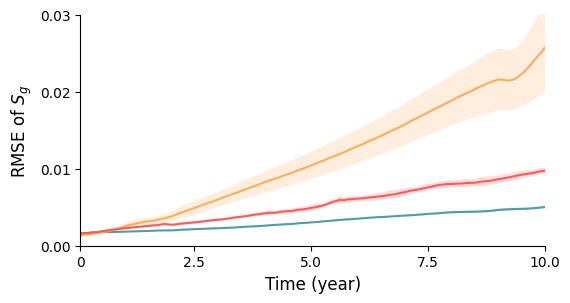

In [284]:
plt.figure(figsize=(6, 3))
plt.plot(sr_sat_mean, label='$CO_2$ plume monitoring', color='#4f9da6', linestyle='-', linewidth=1.5)
plt.fill_between(range(sr_sat_mean.shape[0]), sr_sat_mean - sr_sat_std, sr_sat_mean + sr_sat_std, color='#4f9da6', alpha=0.2, edgecolor='none')
plt.plot(sparse_6_sat_mean, label='6 monitoring wells', color='#ffad5a', linestyle='-', linewidth=1.5)
plt.fill_between(range(sparse_6_sat_mean.shape[0]), sparse_6_sat_mean - sparse_6_sat_std, sparse_6_sat_mean + sparse_6_sat_std, color='#ffad5a', alpha=0.2, edgecolor='none')
plt.plot(sparse_18_sat_mean, label='18 monitoring wells', color='#ff5959', linestyle='-', linewidth=1.5)
plt.fill_between(range(sparse_18_sat_mean.shape[0]), sparse_18_sat_mean - sparse_18_sat_std, sparse_18_sat_mean + sparse_18_sat_std, color='#ff5959', alpha=0.2, edgecolor='none')

plt.xlabel('Time (year)', fontsize=12)
plt.ylabel('RMSE of $S_g$', fontsize=12)
# plt.legend(frameon=False, loc='upper left', fontsize=12)
plt.xlim(0, 127)
plt.ylim(0, 0.03)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.yticks([0, 0.01, 0.02, 0.03])
# plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/[rebuttle]figs/RMSE_sat_line.pdf', bbox_inches='tight')
plt.show()

mean shape: (128,), std shape: (128,)


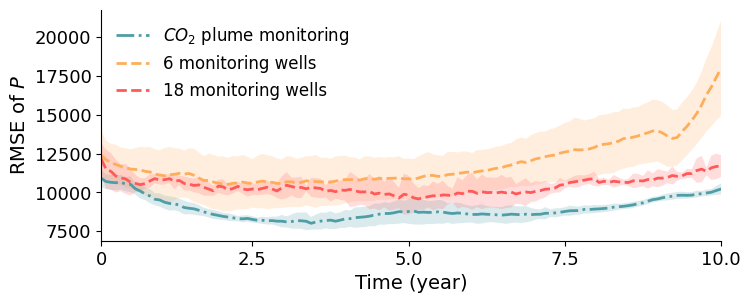

In [11]:
def rmse(a, b):
    return np.sqrt((a - b)**2).mean()

def calculate_pre_rmse(ref, gene):
    rmse_list = []
    ref_sat = ref[..., 0]
    for i in range(gene.shape[0]):
        sat = gene[i, :, ..., 0]
        for t in range(gene.shape[1]):
            rmse_value = rmse(ref_sat[t, ...], sat[t, ...])
            rmse_list.append(rmse_value)
    rmse_list = np.array(rmse_list)
    rmse_List = rmse_list.reshape(gene.shape[0], gene.shape[1])
    rmse_mean = np.mean(rmse_List, axis=0)
    rmse_std = np.std(rmse_List, axis=0)
    return rmse_mean, rmse_std

sr_sat_mean, sr_sat_std = calculate_pre_rmse(REF, sr)
sparse_6_sat_mean, sparse_6_sat_std = calculate_pre_rmse(REF, sparse_6)
sparse_18_sat_mean, sparse_18_sat_std = calculate_pre_rmse(REF, sparse_18)
print(f'mean shape: {sr_sat_mean.shape}, std shape: {sr_sat_std.shape}')


plt.figure(figsize=(8, 3))
plt.plot(sr_sat_mean, label='$CO_2$ plume monitoring', color='#4f9da6', linestyle='-.', linewidth=2)
plt.fill_between(range(sr_sat_mean.shape[0]), sr_sat_mean - sr_sat_std, sr_sat_mean + sr_sat_std, color='#4f9da6', alpha=0.2, edgecolor='none')
plt.plot(sparse_6_sat_mean, label='6 monitoring wells', color='#ffad5a', linestyle='--', linewidth=2)
plt.fill_between(range(sparse_6_sat_mean.shape[0]), sparse_6_sat_mean - sparse_6_sat_std, sparse_6_sat_mean + sparse_6_sat_std, color='#ffad5a', alpha=0.2, edgecolor='none')
plt.plot(sparse_18_sat_mean, label='18 monitoring wells', color='#ff5959', linestyle='--', linewidth=2)
plt.fill_between(range(sparse_18_sat_mean.shape[0]), sparse_18_sat_mean - sparse_18_sat_std, sparse_18_sat_mean + sparse_18_sat_std, color='#ff5959', alpha=0.2, edgecolor='none')

plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('RMSE of $P$', fontsize=14)
plt.legend(frameon=False, loc='upper left', fontsize=12)
plt.xlim(0, 127)
# plt.ylim(7000, 22000)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/figs/RMSE_pre_line.pdf', bbox_inches='tight')
plt.show()

In [16]:
def get_ensemble_sat(gene):
    ensemble_sat = []
    for i in range(gene.shape[0]):
        ensemble_sat.append(gene[i, :, 31, 29, 1])
    return np.array(ensemble_sat)

allt_sat = get_ensemble_sat(allt)
quatert_sat = get_ensemble_sat(quatert)
halft_sat = get_ensemble_sat(halft)
threet_sat = get_ensemble_sat(threet)
sparset_sat = get_ensemble_sat(sparset)
print(f"allt_sat shape: {allt_sat.shape}, halft_sat shape: {halft_sat.shape}, sparset_sat shape: {sparset_sat.shape}, quatert_sat shape: {quatert_sat.shape}, threet_sat shape: {threet_sat.shape}")

allt_sat shape: (10, 128), halft_sat shape: (10, 128), sparset_sat shape: (10, 128), quatert_sat shape: (10, 128), threet_sat shape: (10, 128)


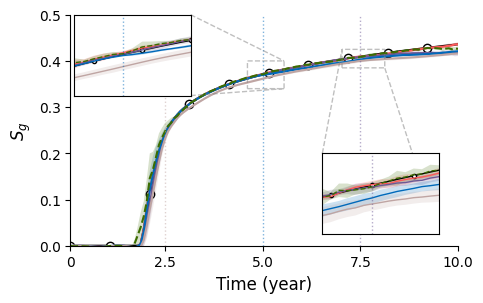

In [309]:
def plot_mean_and_std(data, label=None, color='blue', ls='-', alpha=0.2, ax=None, linewidth=1.5):
    if ax is None:
        ax = plt.gca()
    mean_data = np.mean(data, axis=0)
    std_data = np.std(data, axis=0)
    ax.plot(mean_data, label=label, color=color, linestyle=ls, linewidth=linewidth)
    ax.fill_between(range(mean_data.shape[0]), mean_data - std_data, mean_data + std_data, 
                     color=color, alpha=alpha, edgecolor='none')

colors = ['#ff5959', '#6c5995', '#0069ba', '#bfa5a3', "#3c6d00"]

plt.figure(figsize=(5, 3))
# plt.plot(np.arange(128), REF[:, 31, 29, 1], label='Reference', color='#1a0841', linestyle='-', linewidth=1.5,)
plt.plot(np.arange(128), REF[:, 31, 29, 1], marker='o', markevery=13, markersize=6, markerfacecolor='white', markeredgecolor='black',
        label='Reference', color="black", linestyle='-', linewidth=1.5)


plot_mean_and_std(allt_sat, label="Full observation", color=colors[0], ls='-')
plot_mean_and_std(threet_sat, label="More partial observation", color=colors[1], ls='-')
plot_mean_and_std(halft_sat, label="Partial observation", color=colors[2], ls='-')
plot_mean_and_std(quatert_sat, label="Less partial observation", color=colors[3], ls='-')
plot_mean_and_std(sparset_sat, label='Sparse observation', color=colors[4], ls='--')


plt.axvline(x=31, color=colors[3], linestyle=':', alpha=0.5, lw=1)
plt.axvline(x=63, color=colors[2], linestyle=':', alpha=0.5, lw=1)
plt.axvline(x=95, color=colors[1], linestyle=':', alpha=0.5, lw=1)

plt.xlabel('Time (year)', fontsize=12)
plt.ylabel('$S_g$', fontsize=12)
# plt.legend(frameon=False, loc='lower right', fontsize=12)
plt.xlim(0, 127)
plt.ylim(0, 0.5)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
# plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
# ---- 第一个放大 ----
axins1 = ax.inset_axes([0.65, 0.05, 0.3, 0.35])  # 放右下角，避免重叠

axins1.plot(np.arange(128), REF[:, 31, 29, 1], marker='o', markevery=5, markersize=3, 
           markerfacecolor='white', markeredgecolor='black',
           color="black", linestyle='-', linewidth=1)
plot_mean_and_std(allt_sat, color=colors[0], ls='-', ax=axins1, linewidth=1)
plot_mean_and_std(threet_sat, color=colors[1], ls='-', ax=axins1, linewidth=1)
plot_mean_and_std(halft_sat, color=colors[2], ls='-', ax=axins1, linewidth=1)
plot_mean_and_std(quatert_sat, color=colors[3], ls='-', ax=axins1, linewidth=1)
plot_mean_and_std(sparset_sat, color=colors[4], ls='--', ax=axins1, linewidth=1)
axins1.axvline(x=95, color=colors[1], linestyle=':', alpha=0.5, lw=1)

axins1.set_xlim(89, 103)
axins1.set_ylim(0.385, 0.425)
axins1.set_xticks([])
axins1.set_yticks([])
ax.indicate_inset_zoom(axins1, edgecolor="0.5", linestyle='--')

# ---- 第二个放大 ----
axins2 = ax.inset_axes([0.01, 0.65, 0.3, 0.35])  # 放左上角，避免重叠

axins2.plot(np.arange(128), REF[:, 31, 29, 1], marker='o', markevery=5, markersize=3, 
           markerfacecolor='white', markeredgecolor='black',
           color="black", linestyle='-', linewidth=1)
plot_mean_and_std(allt_sat, color=colors[0], ls='-', ax=axins2, linewidth=1)
plot_mean_and_std(threet_sat, color=colors[1], ls='-', ax=axins2, linewidth=1)
plot_mean_and_std(halft_sat, color=colors[2], ls='-', ax=axins2, linewidth=1)
plot_mean_and_std(quatert_sat, color=colors[3], ls='-', ax=axins2, linewidth=1)
plot_mean_and_std(sparset_sat, color=colors[4], ls='--', ax=axins2, linewidth=1)
axins2.axvline(x=63, color=colors[2], linestyle=':', alpha=0.5, lw=1)
axins2.set_xlim(58, 70)   # 调整放大区域
axins2.set_ylim(0.34, 0.4)
axins2.set_xticks([])
axins2.set_yticks([])
ax.indicate_inset_zoom(axins2, edgecolor="0.5", linestyle='--')


plt.savefig('Norway_outputs/[rebuttle]figs/Sat_line_t.pdf', bbox_inches='tight')
plt.show()

In [17]:
def get_ensemble_sat_all_points(gene):
    ensemble_sat = []
    for i in range(gene.shape[0]):
        ensemble_sat.append(gene[i, -1, :, :, 1])
    return np.array(ensemble_sat)

allt_sat = get_ensemble_sat_all_points(allt)
quatert_sat = get_ensemble_sat_all_points(quatert)
halft_sat = get_ensemble_sat_all_points(halft)
threet_sat = get_ensemble_sat_all_points(threet)
sparset_sat = get_ensemble_sat_all_points(sparset)

gt_sat = REF[-1, :, :, 1]
gt_k = REF[0, :, :, 2]
print(f"allt_sat shape: {allt_sat.shape}, quatert_sat shape: {quatert_sat.shape}, halft_sat shape: {halft_sat.shape}, threet_sat shape: {threet_sat.shape},sparset_sat shape: {sparset_sat.shape}")
print(f"allt_k shape: {allt_k.shape}, quatert_k shape: {quatert_k.shape}, halft_k shape: {halft_k.shape}, threet_k shape: {threet_k.shape}, sparset_k shape: {sparset_k.shape}")
print(f"gt sat shape: {gt_sat.shape}")
print(f"gt k shape: {gt_k.shape}")

allt_sat shape: (10, 64, 118), quatert_sat shape: (10, 64, 118), halft_sat shape: (10, 64, 118), threet_sat shape: (10, 64, 118),sparset_sat shape: (10, 64, 118)
allt_k shape: (10, 64, 118), quatert_k shape: (10, 64, 118), halft_k shape: (10, 64, 118), threet_k shape: (10, 64, 118), sparset_k shape: (10, 64, 118)
gt sat shape: (64, 118)
gt k shape: (64, 118)


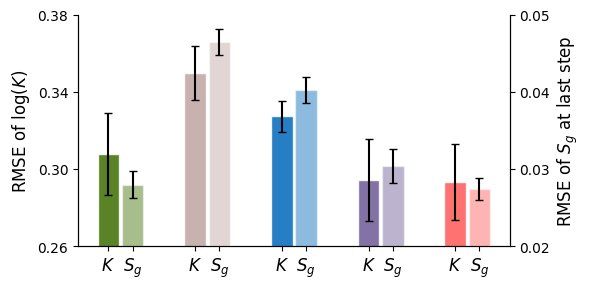

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 计算每个sample的RMSE，然后取mean和std
# ============================================================
def compute_rmse_stats(samples, gt):
    rmse_list = []
    for i in range(samples.shape[0]):
        rmse_i = np.sqrt(np.mean((samples[i] - gt) ** 2))
        rmse_list.append(rmse_i)
    rmse_list = np.array(rmse_list)
    return rmse_list.mean(), rmse_list.std()

# Permeability
allt_k_mean, allt_k_std = compute_rmse_stats(allt_k, gt_k)
threet_k_mean, threet_k_std = compute_rmse_stats(threet_k, gt_k)
halft_k_mean, halft_k_std = compute_rmse_stats(halft_k, gt_k)
quatert_k_mean, quatert_k_std = compute_rmse_stats(quatert_k, gt_k)
sparset_k_mean, sparset_k_std = compute_rmse_stats(sparset_k, gt_k)

# Saturation (最后一步)
allt_sat_mean, allt_sat_std = compute_rmse_stats(allt_sat, gt_sat)
threet_sat_mean, threet_sat_std = compute_rmse_stats(threet_sat, gt_sat)
halft_sat_mean, halft_sat_std = compute_rmse_stats(halft_sat, gt_sat)
quatert_sat_mean, quatert_sat_std = compute_rmse_stats(quatert_sat, gt_sat)
sparset_sat_mean, sparset_sat_std = compute_rmse_stats(sparset_sat, gt_sat)

# ============================================================
# 画图
# ============================================================
k_means = [sparset_k_mean, quatert_k_mean, halft_k_mean, threet_k_mean, allt_k_mean]
k_stds = [sparset_k_std, quatert_k_std, halft_k_std, threet_k_std, allt_k_std]
sat_means = [sparset_sat_mean, quatert_sat_mean, halft_sat_mean, threet_sat_mean, allt_sat_mean]
sat_stds = [sparset_sat_std, quatert_sat_std, halft_sat_std, threet_sat_std, allt_sat_std]

colors = ['#3c6d00', '#bfa5a3', '#0069ba', '#6c5995', '#ff5959', ]
group_labels = ['Sparse obs.', '25% obs.', '50% obs.', '75% obs.', 'Full obs.']

n_groups = len(colors)
width = 0.35
group_width = 2 * width + 0.1  # 组内两个柱子 + 小间隔
group_gap = 0.6                 # 组间间隔
x_centers = np.arange(n_groups) * (group_width + group_gap)

fig, ax1 = plt.subplots(figsize=(6, 3))
ax2 = ax1.twinx()

for i in range(n_groups):
    ax1.bar(x_centers[i] - width/2 - 0.02, k_means[i], width, yerr=k_stds[i],
            capsize=3, color=colors[i], edgecolor='white', alpha=0.85)
    ax2.bar(x_centers[i] + width/2 + 0.02, sat_means[i], width, yerr=sat_stds[i],
            capsize=3, color=colors[i], edgecolor='white', alpha=0.45)

# x轴标注
tick_positions = []
tick_labels = []
for i in range(n_groups):
    tick_positions.append(x_centers[i] - width/2 - 0.02)
    tick_positions.append(x_centers[i] + width/2 + 0.02)
    tick_labels.append('$K$')
    tick_labels.append('$S_g$')

ax1.set_xticks(tick_positions)
ax1.set_xticklabels(tick_labels, fontsize=12)
ax1.set_ylabel('RMSE of $\\log(K)$', fontsize=12)
ax2.set_ylabel('RMSE of $S_g$ at last step', fontsize=12)
# ax1.tick_params(axis='y', labelsize=12)
# ax2.tick_params(axis='y', labelsize=12)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_ylim(0.26, 0.38)
ax1.set_yticks([0.26, 0.30, 0.34, 0.38])
ax2.set_ylim(0.02, 0.05)
ax2.set_yticks([0.02, 0.03, 0.04, 0.05])

# 图例用颜色区分组
# legend_handles = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], alpha=0.85) for i in range(n_groups)]
# ax.legend(legend_handles, group_labels, frameon=False, fontsize=10, 
#           loc='upper right', ncol=2)

plt.tight_layout()
plt.savefig('Norway_outputs/[rebuttle]figs/rmse_bar.pdf', bbox_inches='tight')
plt.show()

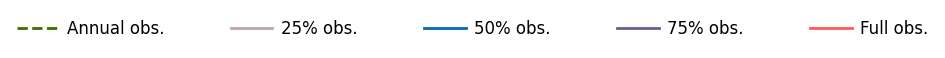

In [19]:
# 自定义 6 个图例元素
from matplotlib.lines import Line2D

colors = ['#3c6d00', '#bfa5a3', '#0069ba', '#6c5995', '#ff5959']
group_labels = ['Annual obs.', '25% obs.', '50% obs.', '75% obs.', 'Full obs.']

legend_elements = [
    Line2D([0], [0], color=colors[0], lw=2, ls='--', label=group_labels[0]),
    Line2D([0], [0], color=colors[1], lw=2, ls='-', label=group_labels[1]),
    Line2D([0], [0], color=colors[2], lw=2, ls='-', label=group_labels[2]),
    Line2D([0], [0], color=colors[3], lw=2, ls='-', label=group_labels[3]),
    Line2D([0], [0], color=colors[4], lw=2, ls='-', label=group_labels[4]),
]

# 创建一个空的透明 subplot
fig, ax = plt.subplots(figsize=(6, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=5,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=4,  # space between columns
    fontsize=12,
)

# plt.tight_layout()
plt.savefig('Norway_outputs/[rebuttle]figs/LEGEND_LINE_2.pdf', bbox_inches='tight')
plt.show()

### old code

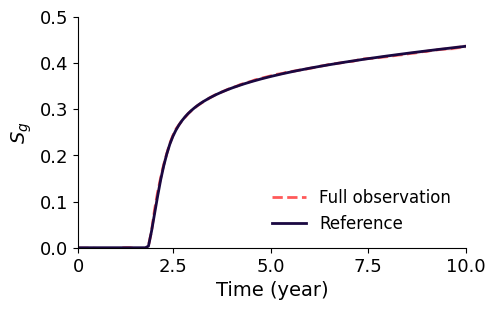

In [17]:
plt.figure(figsize=(5, 3))
plot_mean_and_std(allt_sat, label='Full observation', color='#ff5959', ls='--')
# plot_mean_and_std(halft_k[:, :, 41], label='Initial half time steps', color='#f787bd', ls='--')
# plot_mean_and_std(sparset_k[:, :, 41], label='Every year', color="#8e4f4a", ls='--')
plt.plot(np.arange(128), REF[:, 31, 29, 1], label='Reference', color='#1a0841', linestyle='-', linewidth=2)
plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('$S_g$', fontsize=14)
plt.legend(frameon=False, loc='lower right', fontsize=12)
plt.xlim(0, 127)
plt.ylim(0, 0.5)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/figs/Sat_line_all.pdf', bbox_inches='tight')
plt.show()

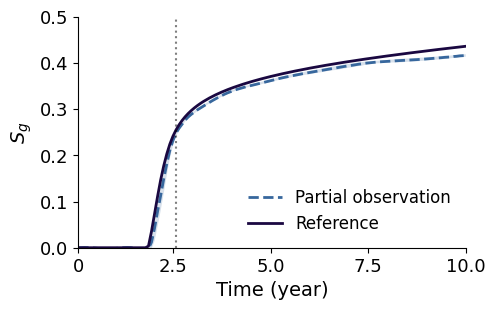

In [18]:
plt.figure(figsize=(5, 3))
# plot_mean_and_std(allt_sat, label='All time steps', color='#ff5959', ls='--')
plot_mean_and_std(halft_sat, label='Partial observation', color='#37679d', ls='--')
# plot_mean_and_std(sparset_k[:, :, 41], label='Every year', color="#8e4f4a", ls='--')
plt.plot(np.arange(128), REF[:, 31, 29, 1], label='Reference', color='#1a0841', linestyle='-', linewidth=2)
plt.axvline(x=32, color='black', linestyle=':', alpha=0.5)

plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('$S_g$', fontsize=14)
plt.legend(frameon=False, loc='lower right', fontsize=12)
plt.xlim(0, 127)
plt.ylim(0, 0.5)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/figs/Sat_line_halft.pdf', bbox_inches='tight')
plt.show()

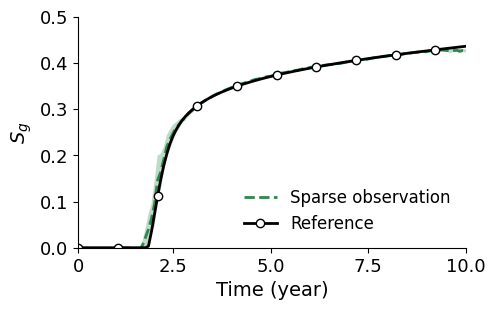

In [19]:
plt.figure(figsize=(5, 3))
# plot_mean_and_std(allt_sat, label='All time steps', color='#ff5959', ls='--')
# plot_mean_and_std(halft_k[:, :, 41], label='Initial half time steps', color='#f787bd', ls='--')
plot_mean_and_std(sparset_sat, label='Sparse observation', color="#2E874D", ls='--', alpha=0.3)
plt.plot(np.arange(128), REF[:, 31, 29, 1], marker='o', markevery=13, markersize=6, markerfacecolor='white', markeredgecolor='black',
        label='Reference', color="black", linestyle='-', linewidth=2)

plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('$S_g$', fontsize=14)
plt.legend(frameon=False, loc='lower right', fontsize=12)
plt.xlim(0, 127)
plt.ylim(0, 0.5)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Norway_outputs/figs/Sat_line_sparset.pdf', bbox_inches='tight')
plt.show()

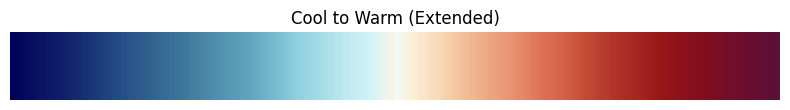

In [20]:
from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]


rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)


x = rgb_points[:, 0]

r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]

colors = list(zip(x, zip(r, g, b)))

mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)
gradient = np.linspace(0, 1, 256).reshape(1, -1)
plt.figure(figsize=(8, 1.2))
plt.imshow(gradient, aspect='auto', cmap=mycmap)
plt.axis("off")
plt.title("Cool to Warm (Extended)")
plt.tight_layout()
plt.show()

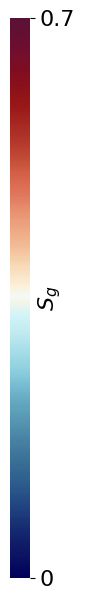

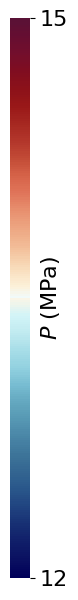

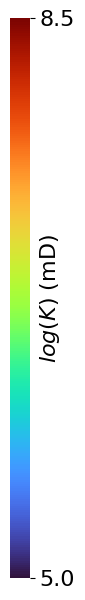

In [21]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.7)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([0, 0.7])
cbar.ax.set_yticklabels(["0", "0.7"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("Norway_outputs/figs/colorbar_sat.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = mycmap
norm = colors.Normalize(vmin=12, vmax=15)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([12, 15])
cbar.ax.set_yticklabels(["12", "15"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$P$ (MPa)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("Norway_outputs/figs/colorbar_pre.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=5, vmax=8.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([5, 8.5])
cbar.ax.set_yticklabels(["5.0", "8.5"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("Norway_outputs/figs/colorbar_k.pdf", bbox_inches='tight')
plt.show()